# Graphite crust on Mercury

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LogNorm, Normalize, SymLogNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import cmcrameri.cm as cmc
from copy import deepcopy

import utils.load_grid as lg

from proteus.interior_energetics.spider import read_jsons
from proteus.utils.constants import CONDENSATE_HELD_MASS_KG
from proteus.utils.constants import (CONDENSATE_SATURATED_ACTIVITY, condensate_conductivity,
                                     condensate_density)
from proteus.utils.helper import CommentFromStatus

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
%matplotlib inline
# %config InlineBackend.figure_format = 'retina'

In [3]:
pgrid_dir = "data/scratch/mercury_graphite_grid_v22"

# Planet mass to extract from the grid's planet.mass_tot axis [M_earth]
mass_idx_analysis = 1

outdir = os.path.join("output", os.path.basename(pgrid_dir) + "_analysis" + f"_mass{mass_idx_analysis:d}")
os.makedirs(outdir, exist_ok=True)

SATURATED = CONDENSATE_SATURATED_ACTIVITY   # activity at and above which graphite counts as saturated
CRUST_MIN_M = 1e-3                          # thinner graphite layers count as no crust [m]
RHO_GRAPHITE = condensate_density["C"]      # [kg m-3]
K_GRAPHITE = condensate_conductivity["C"]   # [W m-1 K-1]
STATUS_ESCAPED = 15                         # run stopped because the atmosphere escaped

# Mercury's present-day surface fO2 relative to IW (Sossi review)
MERCURY_DIW, MERCURY_DIW_ERR = -5.0, 0.4

# Low-reflectance material: initial crustal thickness, and its graphite equivalent [m]
LRM_CRUST_M = 4300.0
LRM_GRAPHITE_M = 120.0

In [4]:
cases = lg.get_cases(pgrid_dir, only_completed=False)
cfgs = lg.load_configs(cases)

# Keep the cases at the chosen planet mass; helpfiles are read for these only
mass = np.array(lg.access_configs(cfgs, "planet.mass_tot"), dtype=float)
MASS_VALUES = np.unique(mass)
MASS_TOT = MASS_VALUES[mass_idx_analysis]
keep = np.isclose(mass, MASS_TOT, rtol=1e-6, atol=0.0)
assert keep.any(), f"MASS_TOT = {MASS_TOT} is not on the grid's mass axis {MASS_VALUES}"
cases = [c for c, k in zip(cases, keep) if k]
cfgs = [c for c, k in zip(cfgs, keep) if k]
print(f"Planet mass {MASS_TOT:g} M_earth (grid: {MASS_VALUES} M_earth): "
      f"{len(cases)} of {len(keep)} cases")

helps, _ = lg.load_helpfiles(cases)

Configs:   0%|          | 0/288 [00:00<?, ?it/s]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false


Atmodeller initialized with double precision (float64)


Configs:   0%|          | 1/288 [00:04<20:02,  4.19s/it]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false


Planet mass 0.1368 M_earth (grid: [0.0553 0.1368] M_earth): 144 of 288 cases


Helpfiles: 100%|██████████| 144/144 [00:07<00:00, 20.38it/s]


In [5]:

def cfg_array(key, dtype=float):
    return np.array(lg.access_configs(cfgs, key), dtype=dtype)

# Arrays of configuration values for all completed cases
dIW = cfg_array("outgas.fO2_shift_IW")
Cb = cfg_array("planet.elements.C_budget")
cond = cfg_array("outgas.atmodeller.include_condensates", bool)
eta = cfg_array("escape.zephyrus.efficiency")
status = np.array([lg.get_status(c) for c in cases])
C_mode = lg.access_configs(cfgs, "planet.elements.C_mode")[0]
C_label = {"ppmw": "C [ppmw]", "C/H": "C/H mass ratio", "kg": "C [kg]"}.get(C_mode, "C budget")

print(f"Unique status values: {np.unique(status)}")
print("Solidified case numbers:", [cases[int(idx[0])].split("case_")[1] for idx in np.argwhere(status == 10)])
print("NetFlux    case numbers:", [cases[int(idx[0])].split("case_")[1] for idx in np.argwhere(status == 14)])
print("Escaped    case numbers:", [cases[int(idx[0])].split("case_")[1] for idx in np.argwhere(status == 15)])

# get other cases that didn't solidify, didn't reach net flux, and didn't escape
mask = ~np.isin(status, (10, 14, 15))
print("Other      case numbers:", [cases[int(idx[0])].split("case_")[1] for idx in np.argwhere(mask)])


# values for the escape efficiency of the off and on arms
ETA_OFF, ETA_ON = np.unique(eta)   
ESC_LABEL = {ETA_OFF: "Escape off", ETA_ON: rf"Escape on ($\eta$ = {ETA_ON:g})"}

# labels for the saturation condition of the off and on arms
SAT_LABEL = {True: "Saturation on", False: "Saturation off"}

print(f"{len(cases)} completed cases; carbon given as {C_mode}")

print("Summary of completed cases by saturation and escape efficiency:")
pd.crosstab([pd.Series(cond, name="saturation on/off?"), pd.Series(eta, name="escape eff.")],
            pd.Series([CommentFromStatus(s) for s in status], name="stop reason ->"))



Unique status values: [10 15]
Solidified case numbers: ['000001', '000003', '000005', '000007', '000009', '000011', '000013', '000015', '000017', '000019', '000021', '000023', '000025', '000027', '000029', '000031', '000033', '000035', '000037', '000039', '000041', '000043', '000045', '000049', '000051', '000053', '000055', '000057', '000059', '000061', '000063', '000065', '000067', '000069', '000071', '000073', '000075', '000077', '000079', '000081', '000083', '000085', '000087', '000089', '000091', '000093', '000097', '000099', '000101', '000103', '000105', '000107', '000109', '000111', '000113', '000115', '000117', '000119', '000121', '000123', '000125', '000127', '000129', '000131', '000133', '000135', '000137', '000139', '000141', '000145', '000147', '000149', '000151', '000153', '000155', '000157', '000159', '000161', '000163', '000165', '000167', '000169', '000171', '000173', '000175', '000177', '000179', '000181', '000183', '000185', '000187', '000189', '000191', '000193', '000

stop reason ->                  Completed (solidified)  \
saturation on/off? escape eff.                           
False              0.0                              36   
                   0.1                              36   
True               0.0                              36   
                   0.1                              33   

stop reason ->                  Completed (volatiles escaped)  
saturation on/off? escape eff.                                 
False              0.0                                      0  
                   0.1                                      0  
True               0.0                                      0  
                   0.1                                      3

In [6]:
COLS = ["Time", "C_cd_activity", "C_cd_kg", "R_int", "T_magma", "T_surf", "F_int", "F_atm",
        "Phi_global", "P_surf", "boundary_layer_thickness", "boundary_layer_conductivity",
        "C_kg_atm", "C_kg_condensed", "CO_bar", "atm_converged", "bond_albedo",
        "C_kg_liquid", "C_kg_solid", "C_kg_total"]

# loop through all cases, collecting time series and summary data for each
rows, series = [], {}
for case, hf, x, y, on, e, s in zip(cases, helps, dIW, Cb, cond, eta, status):

    # Read the time series from the helpfile
    ts = {k: np.array(hf[k], dtype=float) for k in COLS}
    #    compute graphite thickness assuming constant rho
    ts["thick"] = ts["C_cd_kg"] / (4.0 * np.pi * ts["R_int"] ** 2) / RHO_GRAPHITE 
    #    compute surface temperature difference
    ts["dT_skin"] = ts["T_magma"] - ts["T_surf"]     
    #    store timeseries for this case, as dict keyed by parameters                               
    series[(x, y, on, e)] = ts

    # get mask of saturated times
    sat = np.flatnonzero(ts["C_cd_activity"] >= SATURATED)
    skin = ts["boundary_layer_thickness"] > 0

    # store summary data for this case, appended to list
    rows.append(dict(case=os.path.basename(case), 
                     dIW=x, C=y, cond=on, eta=e, # <- sorted by these parameters
                     status=s,
                     time_end=ts["Time"][-1], 
                     T_magma_end=ts["T_magma"][-1],
                     T_surf_end=ts["T_surf"][-1], 
                     P_surf_end=ts["P_surf"][-1],
                     act_max=ts["C_cd_activity"].max(), 
                     thickness_m=ts["thick"][-1],
                     onset_yr=ts["Time"][sat[0]] if len(sat) else np.nan,
                     dT_skin_end=ts["dT_skin"][-1],
                     dT_skin_max=ts["dT_skin"][skin].max() if skin.any() else 0.0))

# Convert the summary list data to dataframe, sorted by parameters, and write to CSV
summary = pd.DataFrame(rows).sort_values(["cond", "eta", "dIW", "C"]).reset_index(drop=True)
summary.to_csv(os.path.join(outdir, "summary.csv"), index=False)
print(np.shape(summary))

(144, 15)


In [7]:
# Arrange onto the 2D parameter plane
xs = np.unique(summary["dIW"])
ys = np.unique(summary["C"])

def arm(on, e):
    """Function to get rows of one A/B arm: saturation on/off and escape efficiency e."""
    return summary[(summary["cond"] == on) & (summary["eta"] == e)]

def on_plane(col, df):
    """Function to get the 2D parameter plane values for a column of the summary dataframe."""

    # Matrix of NaNs by default, with rows = C values and columns = dIW values
    Z = np.full((len(ys), len(xs)), np.nan)

    # Loop through the rows of the dataframe, and fill in the matrix with the column values
    for _, r in df.iterrows():
        Z[np.searchsorted(ys, r["C"]), np.searchsorted(xs, r["dIW"])] = r[col]
    return Z

def cell_edges(v, log=False):
    """Determine cell edges halfway between grid values (geometric midpoints on a log axis)."""
    v = np.log10(v) if log else np.asarray(v, dtype=float)
    if len(v) == 1:
        e = np.array([v[0] - 0.5, v[0] + 0.5])
    else:
        mid = 0.5 * (v[1:] + v[:-1])
        e = np.concatenate([[v[0] - (mid[0] - v[0])], mid, [v[-1] + (v[-1] - mid[-1])]])
    return 10 ** e if log else e

# Cell edges for plotting meshes
x_edges = cell_edges(xs)
y_edges = cell_edges(ys, log=True)

In [8]:
def label(ax, x, y, txt):
    """Cell label with a thin white outline."""
    ax.text(x, y, txt, ha="center", va="center", fontsize=8, color='k', zorder=6,
            path_effects=[pe.withStroke(linewidth=2.0, foreground='w')])

def mesh(ax, Z, cmap, norm, fmt, empty, empty_text):
    """Colour mesh of Z with per-cell labels; cells where `empty` is true are grey."""
    ax.pcolormesh(x_edges, y_edges, np.where(empty, 1.0, np.nan), cmap="Greys",
                  vmin=0, vmax=4, shading="flat")
    pm = ax.pcolormesh(x_edges, y_edges, np.ma.masked_where(empty, Z),
                       cmap=cmap, norm=norm, shading="flat")
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            if empty[i, j]:
                label(ax, x, y, empty_text)
            elif np.isfinite(Z[i, j]):
                label(ax, x, y, fmt(i, j))
    return pm

## Endpoint crust and onset of saturation: escape off and on

Saturation-on runs only: with saturation off no graphite forms (checked above). A `*` marks a run that stopped because its atmosphere escaped (status 15), so its crust is the crust at that time, not at solidification. Both columns share their colour scales.

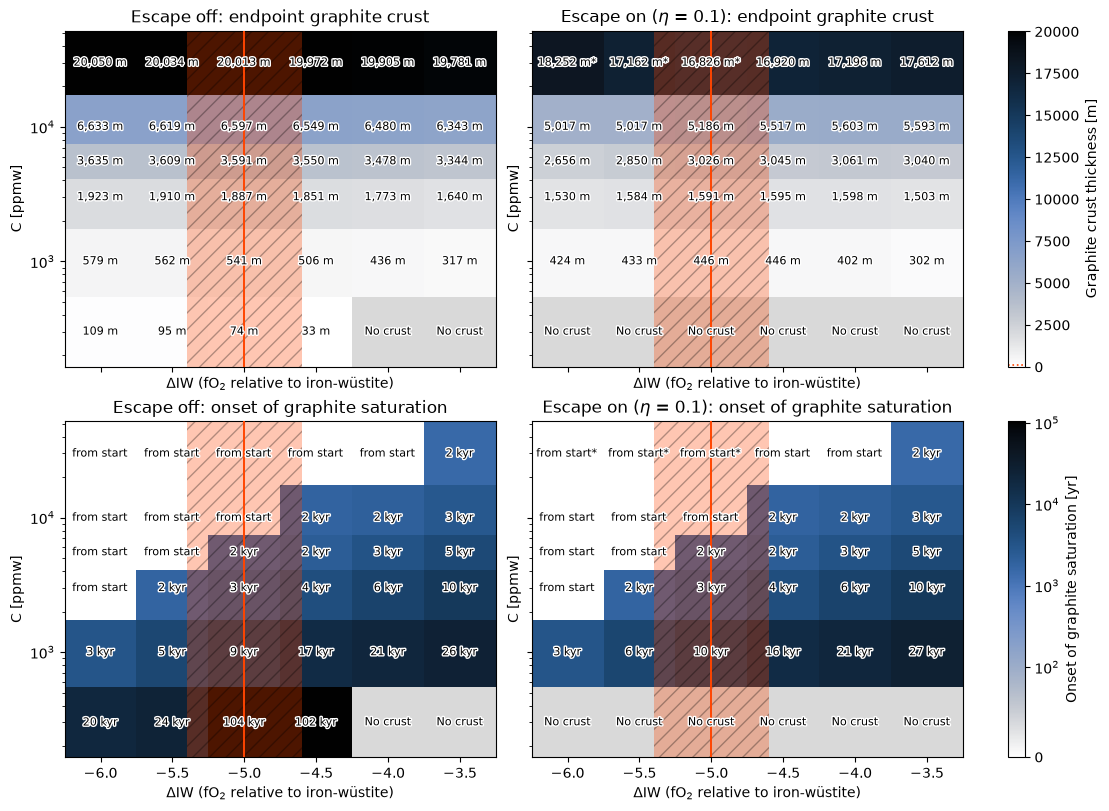

In [9]:
ESC_ARMS = (ETA_OFF, ETA_ON)
Z_t = {e: on_plane("thickness_m", arm(True, e)) for e in ESC_ARMS}
Z_o = {e: on_plane("onset_yr", arm(True, e)) for e in ESC_ARMS}
Z_s = {e: on_plane("status", arm(True, e)) for e in ESC_ARMS}

t_max = max(np.nanmax(Z) for Z in Z_t.values())
o_max = max((np.nanmax(Z) for Z in Z_o.values() if np.isfinite(Z).any()), default=1.0)
norm_t = Normalize(vmin=0, vmax=max(t_max, 1.0))
norm_o = SymLogNorm(vmin=0, vmax=max(o_max, 1.0), linthresh=1e2)

def fmt_onset(v):
    return "from start" if v == 0 else f"{v/1e3:.0f} kyr"

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
for j, e in enumerate(ESC_ARMS):
    star =  lambda i, j: "*" if Z_s[e][i, j] == STATUS_ESCAPED else ""
    Zt, Zo = Z_t[e], Z_o[e]
    pm_t = mesh(axs[0, j], Zt, cmc.oslo_r, norm_t, lambda i, k: f"{Zt[i, k]:,.0f} m{star(i, k)}",
                Zt < CRUST_MIN_M, "No crust")
    pm_o = mesh(axs[1, j], Zo, cmc.oslo_r, norm_o, lambda i, k: fmt_onset(Zo[i, k]) + star(i, k),
                np.isnan(Zo), "No crust")
    axs[0, j].set_title(f"{ESC_LABEL[e]}: endpoint graphite crust")
    axs[1, j].set_title(f"{ESC_LABEL[e]}: onset of graphite saturation")
    for ax in axs[:, j]:
        ax.axvspan(MERCURY_DIW - MERCURY_DIW_ERR, MERCURY_DIW + MERCURY_DIW_ERR,
               facecolor="orangered", edgecolor="k", hatch="//", lw=0, alpha=0.3, zorder=2)
        ax.axvline(MERCURY_DIW, color="orangered", ls="solid", lw=1.4, zorder=3)
        ax.set_yscale("log")
        ax.set_xlabel(r"$\Delta$IW (fO$_2$ relative to iron-wüstite)")
        ax.set_ylabel(C_label)


cb = fig.colorbar(pm_t, ax=axs[0, :], label="Graphite crust thickness [m]")
cb.ax.axhline(LRM_GRAPHITE_M, color="orangered", ls="dotted", lw=1.2)
fig.colorbar(pm_o, ax=axs[1, :], label="Onset of graphite saturation [yr]")

fig.savefig(os.path.join(outdir, "graphite_grid_thickness_onset.pdf"), bbox_inches="tight")
plt.show()

## Graphite crust thickness against time

Saturation-on runs, one panel per carbon budget, one colour per fO$_2$. Solid lines: escape off; dashed lines: escape on. The black lines mark the LRM reference values: the observed initial crustal thickness (4.3 km, dashed) and its graphite equivalent (120 m, dotted). A line starts at the onset of saturation, since the thickness is zero before it. Where the escape-on run follows the escape-off run, its dashed line lies on the solid one.

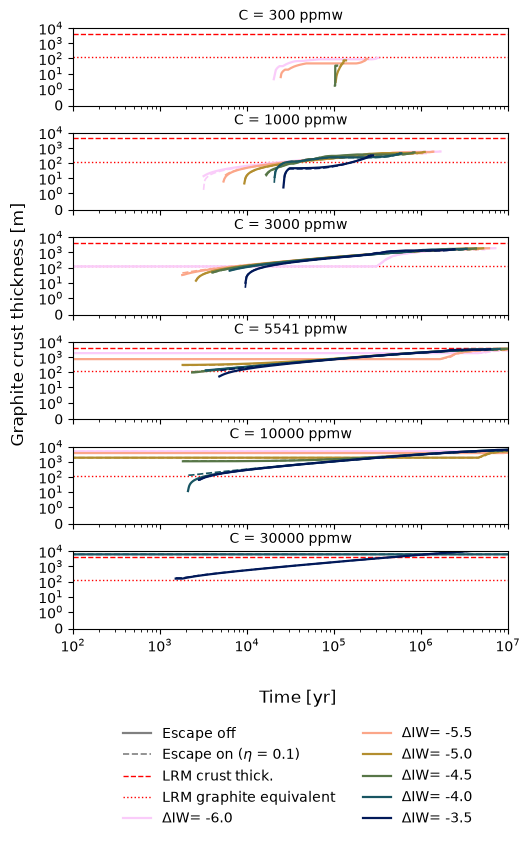

In [10]:
cmap_f = cmc.batlow_r
norm_f = BoundaryNorm(np.concatenate([xs, [xs[-1]]]), cmap_f.N)
ESC_LS = {ETA_OFF: ("-", 1.6), ETA_ON: ("--", 1.2)}

nrow = len(ys)
fig, axs = plt.subplots(nrow, 1, figsize=(6.0, 1.3 * nrow), sharex=True, sharey=True, squeeze=False)
axs = axs[:, 0]
for ax, c in zip(axs, ys):
    for x in xs:
        for e, (ls, lw) in ESC_LS.items():
            if (x, c, True, e) not in series:
                continue
            ts = series[(x, c, True, e)]
            ok = (ts["thick"] > CRUST_MIN_M) & (ts["Time"] > 0)
            if ok.any():
                ax.plot(ts["Time"][ok], ts["thick"][ok], color=cmap_f(norm_f(x)), ls=ls, lw=lw)
    for v, ls in ((LRM_CRUST_M, "--"), (LRM_GRAPHITE_M, ":")):
        ax.axhline(v, color="r", ls=ls, lw=1.0, zorder=1)
    ax.set_xscale("log")
    ax.set_xlim(left=1e2, right=1e7)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_ylim(bottom=0, top=1e4)
    ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
fig.supxlabel("Time [yr]")
fig.supylabel("Graphite crust thickness [m]")

# sm = plt.cm.ScalarMappable(cmap=cmap_f, norm=norm_f)
# cb = fig.colorbar(sm, ax=list(axs), ticks=xs, pad=0.01, fraction=0.03)
# cb.set_label(r"$\Delta$IW")
handles = [Line2D([], [], color="grey", ls="-", lw=1.6), Line2D([], [], color="grey", ls="--", lw=1.2),
           Line2D([], [], color="r", ls="--", lw=1.0), Line2D([], [], color="r", ls=":", lw=1.0)]
labels = [ESC_LABEL[ETA_OFF], ESC_LABEL[ETA_ON], "LRM crust thick.", "LRM graphite equivalent"]

# add fO2 to legend
for x in xs:
    handles.append(Line2D([], [], color=cmap_f(norm_f(x)), lw=1.6))
    labels.append(r"$\Delta$IW" + f"= {x:.1f}")

fig.legend(handles, 
            labels,
            bbox_to_anchor=(0.5, 0.0),
            loc="upper center", ncol=2, frameon=False)

fig.subplots_adjust(hspace=0.35, right=0.85)
fig.savefig(os.path.join(outdir, "graphite_thickness_vs_time.pdf"), bbox_inches="tight")
plt.show()

## Atmospheric carbon with and without graphite saturation

One figure per escape setting. In each, solid lines are the saturation-on run and dashed lines the saturation-off run at the same grid point.

Escape off: 36 grid points have both saturation runs completed


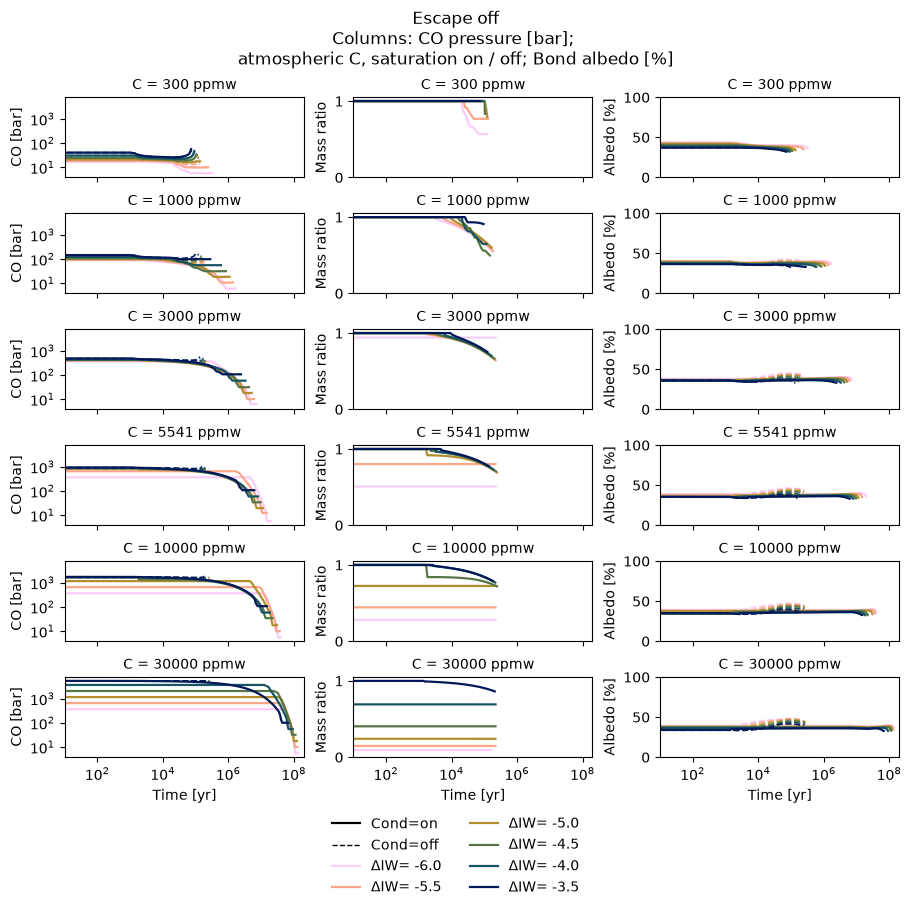

Escape on ($\eta$ = 0.1): 36 grid points have both saturation runs completed


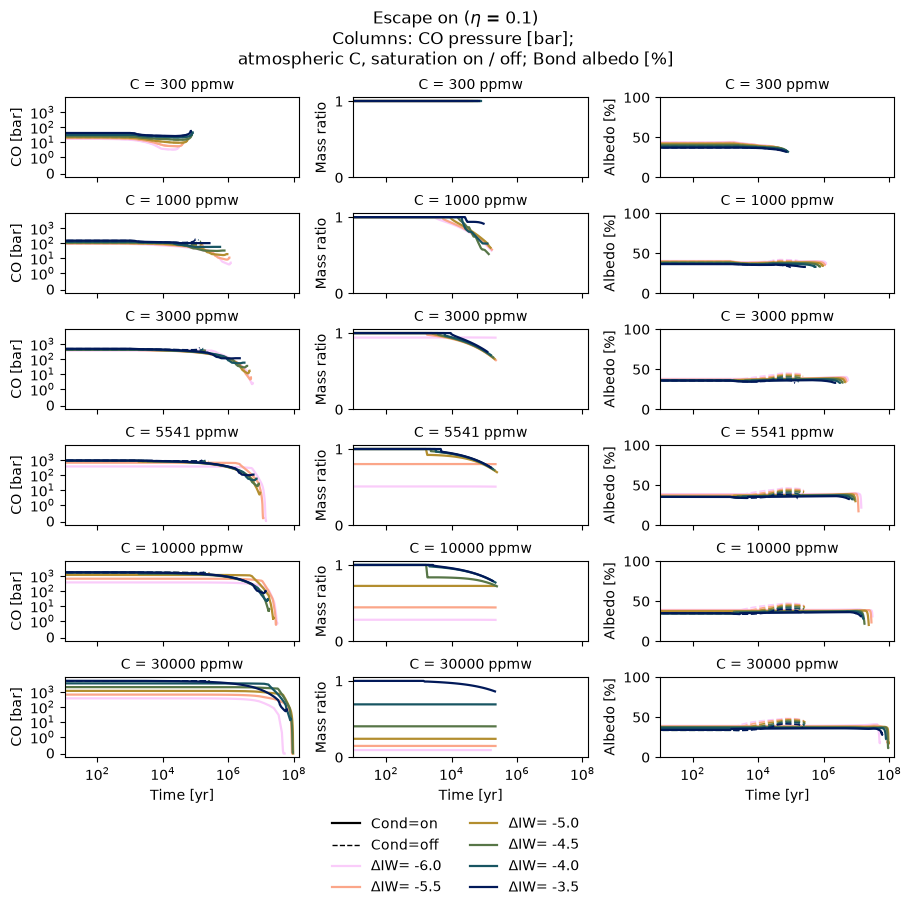

In [11]:
species = "CO"

def ratio_with_without(t_on, c_on, t_off, c_off):
    """Atmospheric C with condensates over that without, at the times of the run with them.

    The run without is interpolated in log-log onto those times, within the time range
    both runs cover.
    """
    keep = np.r_[np.diff(t_off) > 0, True] & (t_off > 0)
    t_off, c_off = t_off[keep], c_off[keep]
    ok = (t_on >= t_off[0]) & (t_on <= t_off[-1])
    c_interp = 10 ** np.interp(np.log10(t_on[ok]), np.log10(t_off), np.log10(c_off))
    return t_on[ok], c_on[ok] / c_interp

def plot_atm_carbon(e):
    """CO pressure, the with/without ratio of atmospheric C and the Bond albedo, for escape efficiency e."""
    pairs = {(x, c): (series[(x, c, True, e)], series[(x, c, False, e)])
             for (x, c, on, ee) in series if on and ee == e and (x, c, False, e) in series}
    print(f"{ESC_LABEL[e]}: {len(pairs)} grid points have both saturation runs completed")
    cmap = cmc.batlow_r
    norm = BoundaryNorm(cell_edges(xs), cmap.N)

    nrow = len(ys)
    fig, axs = plt.subplots(nrow, 3, figsize=(9.0, 1.5 * nrow), sharex=True, sharey="col",
                            squeeze=False, layout="constrained")
    for (ax_m, ax_r, ax_a), c in zip(axs, ys):
        for x in xs:
            if (x, c) not in pairs:
                continue
            col = cmap(norm(x))
            r1, r0 = pairs[(x, c)]
            t1, t0 = r1["Time"], r0["Time"]
            ax_m.plot(t1[t1 > 0], r1[f"{species}_bar"][t1 > 0], color=col, lw=1.6)
            ax_m.plot(t0[t0 > 0], r0[f"{species}_bar"][t0 > 0], color=col, lw=1.2, ls="--")
            ax_r.plot(*ratio_with_without(t1, r1["C_kg_atm"], t0, r0["C_kg_atm"]), color=col, lw=1.6)
            ax_a.plot(t1[t1 > 0], 100 * r1["bond_albedo"][t1 > 0], color=col, lw=1.6)
            ax_a.plot(t0[t0 > 0], 100 * r0["bond_albedo"][t0 > 0], color=col, lw=1.2, ls="--")
        ax_m.set_yscale("symlog", linthresh=1)
        ax_r.set_ylim(0, 1.05)
        ax_a.set_ylim(0, 100)
        for ax in (ax_m, ax_r, ax_a):
            ax.set_xscale("log")
            ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
        ax_m.set_ylabel(f"{species} [bar]")
        ax_r.set_ylabel("Mass ratio")
        ax_a.set_ylabel("Albedo [%]")   # longer labels overrun the row height
    t_max = max(r[k]["Time"][-1] for r in pairs.values() for k in (0, 1))
    axs[0, 0].set_xlim(10, 1.5 * t_max)   # once, after plotting: per-axis calls freeze the right limit
    for ax in axs[-1]:
        ax.set_xlabel("Time [yr]")

    fig.suptitle(f"{ESC_LABEL[e]}\nColumns: {species} pressure [bar]; \n"
                 "atmospheric C, saturation on / off; Bond albedo [%]")
    # sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    # fig.colorbar(sm, ax=axs, ticks=xs, pad=0.01, fraction=0.03).set_label(r"$\Delta$IW")
    # styles = [Line2D([], [], color="k", lw=1.6), Line2D([], [], color="k", lw=1.2, ls="--")]
    # fig.legend(styles, ["With graphite saturation", "Without (condensates off)"],
    #            loc="outside lower center", ncol=2, frameon=False)
    

    styles = [Line2D([], [], color="k", lw=1.6), 
              Line2D([], [], color="k", lw=1.0, ls="--")]
    labels = ["Cond=on", "Cond=off"]
    
    # add fO2 to legend
    for x in xs:
        styles.append(Line2D([], [], color=cmap(norm(x)), lw=1.6))
        labels.append(r"$\Delta$IW" + f"= {x:.1f}")

    fig.legend(styles, 
               labels,
               loc="outside lower center", ncol=2, frameon=False)

    fig.savefig(os.path.join(outdir, f"atm_carbon_with_without_graphite_eta{e:g}.pdf"),
                bbox_inches="tight")
    plt.show()

    # Endpoint of each run: atmospheric C with and without graphite, and the graphite held
    return pd.DataFrame([dict(eta=e, dIW=x, C=c,
                              C_atm_with=r1["C_kg_atm"][-1], C_atm_without=r0["C_kg_atm"][-1],
                              C_graphite=r1["C_kg_condensed"][-1],
                              t_end_with=r1["Time"][-1], t_end_without=r0["Time"][-1])
                         for (x, c), (r1, r0) in sorted(pairs.items())])

end = pd.concat([plot_atm_carbon(e) for e in ESC_ARMS], ignore_index=True)
end["ratio"] = end["C_atm_with"] / end["C_atm_without"]
end.to_csv(os.path.join(outdir, "atm_carbon_with_without_graphite.csv"), index=False)
# end

## Where the carbon goes

Escape-on runs, one panel per grid point, one figure per saturation setting. Each panel stacks the carbon reservoirs as fractions of the planet's carbon at the start of the run (`C_kg_total` at t = 0): dissolved in the magma ocean (`C_kg_liquid`), graphite (`C_kg_condensed`), atmosphere (`C_kg_atm`), and escaped, the drop in the planet's total carbon since the start. Carbon in the solid mantle (`C_kg_solid`) is not shown; the cell prints its largest fraction, and how far the stack is from 1, to check that leaving it out is safe. It also prints the largest magma-ocean fraction, since a region thinner than about 0.01 does not show on the axis. A panel is blank after its run ends.

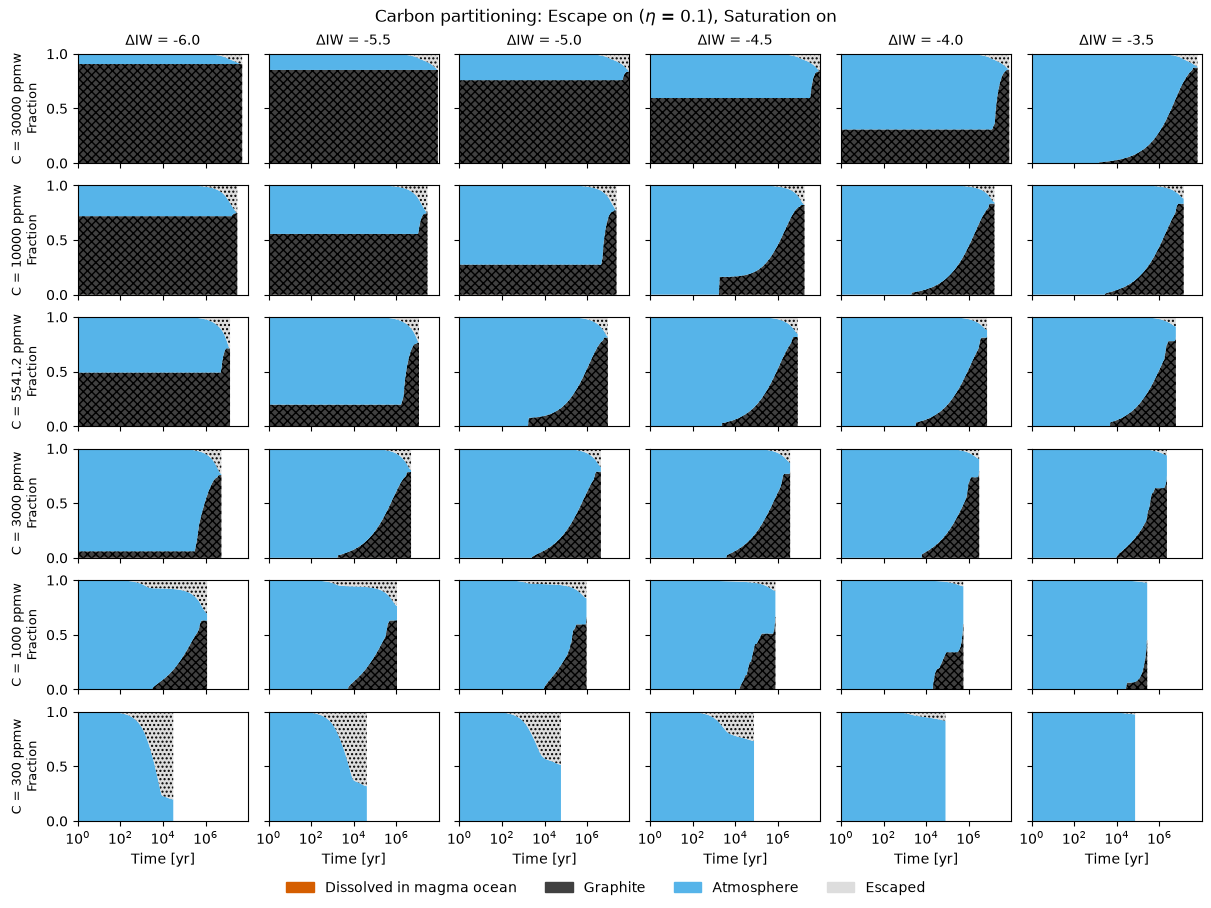

In [12]:
# Carbon reservoirs stacked from the bottom: (helpfile column, label, colour, pattern)
hatch_density = 4
hatch_color = 'k'
C_RESERVOIRS = [("C_kg_liquid", "Dissolved in magma ocean", "#D55E00", ""* hatch_density),
                ("C_kg_condensed", "Graphite", "#404040", "x" * hatch_density),
                ("C_kg_atm", "Atmosphere", "#56B4E9", ""* hatch_density),
                ("escaped", "Escaped", "#dddddd", "." * hatch_density),]

def carbon_fractions(ts):
    """Carbon reservoirs at times > 0, as fractions of the planet's carbon at t = 0."""
    ok = ts["Time"] > 0
    C0 = ts["C_kg_total"][0]
    frac = {k: ts[k][ok] / C0 for k in ("C_kg_liquid", "C_kg_condensed", "C_kg_atm", "C_kg_solid")}
    frac["escaped"] = (C0 - ts["C_kg_total"][ok]) / C0
    return ts["Time"][ok], frac

def plot_carbon_partition(SAT_ON, e=ETA_ON):
    """Stacked carbon reservoirs against time, one panel per grid point, saturation on or off."""
    rows = ys[::-1]   # carbon budget decreasing downwards
    fig, axs = plt.subplots(len(rows), len(xs), figsize=(2.0 * len(xs), 1.5 * len(rows)),
                            sharex=True, sharey=True, squeeze=False, layout="constrained")
    t_lo, t_hi = 1e3, 0.0
    for i, c in enumerate(rows):
        for k, x in enumerate(xs):
            ax = axs[i, k]
            ts = series.get((x, c, SAT_ON, e))
            if ts is not None:
                t, frac = carbon_fractions(ts)
                base = np.zeros_like(t)
                for key, _, colour, pattern in C_RESERVOIRS:
                    ax.fill_between(t, base, base + frac[key], color=colour, lw=0, hatch=pattern, hatchcolor=hatch_color)
                    base = base + frac[key]
                t_lo, t_hi = min(t_lo, t[0]), max(t_hi, t[-1])

            if i == 0:
                ax.set_title(rf"$\Delta$IW = {x:.1f}", fontsize=10)
            if k == 0:
                ax.set_ylabel(f"C = {c:g} ppmw\nFraction", fontsize=9)
    axs[0, 0].set_xscale("log")
    axs[0, 0].set_xlim(t_lo, t_hi) 
    axs[0, 0].set_ylim(0.0, 1.0)
    for ax in axs[-1]:
        ax.set_xlabel("Time [yr]")
    fig.suptitle(f"Carbon partitioning: {ESC_LABEL[e]}, {SAT_LABEL[SAT_ON]}")
    fig.legend([Patch(color=colour, hatch=pattern, hatchcolor=hatch_color) for _, _, colour,pattern in C_RESERVOIRS],
               [lab for _, lab, _, _ in C_RESERVOIRS], loc="outside lower center", ncol=4,
               frameon=False)
    fig.savefig(os.path.join(outdir, f"carbon_partition_sat{int(SAT_ON)}_eta{e:g}.pdf"),
                bbox_inches="tight")
    plt.show()

plot_carbon_partition(True)

## Thermal effect of the graphite skin

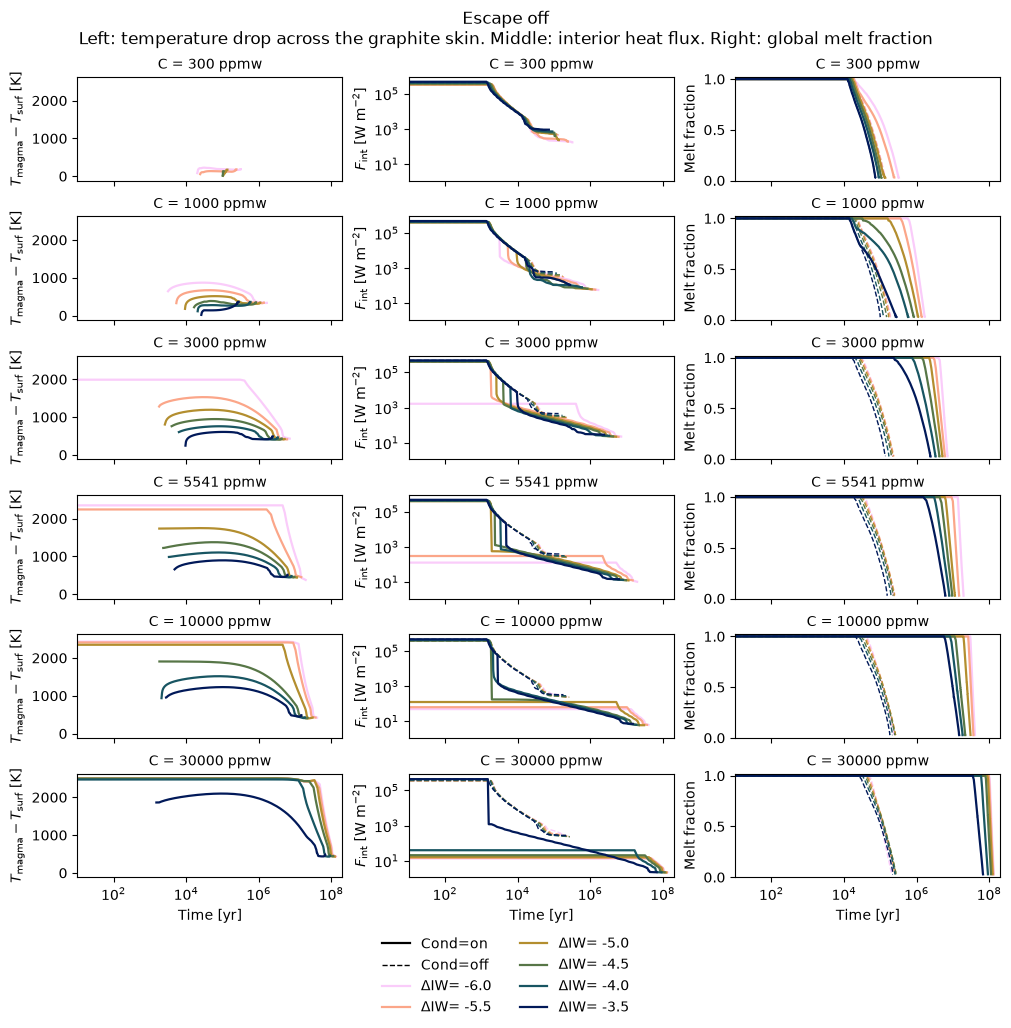

In [13]:
cmap_f = cmc.batlow_r
norm_f = BoundaryNorm(cell_edges(xs), cmap_f.N)

def plot_skin_thermal(e):
    """Skin temperature drop, interior flux and melt fraction against time, escape efficiency e."""
    nrow = len(ys)
    fig, axs = plt.subplots(nrow, 3, figsize=(10.0, 1.7 * nrow), sharex=True, sharey="col",
                            squeeze=False, layout="constrained")
    for (ax_d, ax_f, ax_p), c in zip(axs, ys):
        for x in xs:
            if (x, c, True, e) not in series:
                continue
            col = cmap_f(norm_f(x))
            r1 = series[(x, c, True, e)]
            ok = r1["Time"] > 0
            skin = ok & (r1["boundary_layer_thickness"] > 0)
            if skin.any():
                ax_d.plot(r1["Time"][skin], r1["dT_skin"][skin], color=col, lw=1.6)
            ax_f.plot(r1["Time"][ok], r1["F_int"][ok], color=col, lw=1.6)
            ax_p.plot(r1["Time"][ok], r1["Phi_global"][ok], color=col, lw=1.6)
            if (x, c, False, e) in series:
                r0 = series[(x, c, False, e)]
                ok0 = r0["Time"] > 0
                ax_f.plot(r0["Time"][ok0], r0["F_int"][ok0], color=col, lw=1.0, ls="--")
                ax_p.plot(r0["Time"][ok0], r0["Phi_global"][ok0], color=col, lw=1.0, ls="--")
        ax_f.set_yscale("log")
        ax_p.set_ylim(0, 1.02)
        for ax in (ax_d, ax_f, ax_p):
            ax.set_xscale("log")
            ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
        ax_d.set_ylabel(r"$T_\mathrm{magma} - T_\mathrm{surf}$ [K]")
        ax_f.set_ylabel(r"$F_\mathrm{int}$ [W m$^{-2}$]")
        ax_p.set_ylabel("Melt fraction")
    t_max = max(ts["Time"][-1] for (x, c, on, ee), ts in series.items() if ee == e)
    axs[0, 0].set_xlim(10, 1.5 * t_max)   # once, after plotting: per-axis calls freeze the right limit
    for ax in axs[-1]:
        ax.set_xlabel("Time [yr]")

    fig.suptitle(f"{ESC_LABEL[e]}\nLeft: temperature drop across the graphite skin. "
                 "Middle: interior heat flux. Right: global melt fraction")
    
    styles = [Line2D([], [], color="k", lw=1.6), 
              Line2D([], [], color="k", lw=1.0, ls="--")]
    labels = ["Cond=on", "Cond=off"]
    
    # add fO2 to legend
    for x in xs:
        styles.append(Line2D([], [], color=cmap_f(norm_f(x)), lw=1.6))
        labels.append(r"$\Delta$IW" + f"= {x:.1f}")

    fig.legend(styles, 
               labels,
               loc="outside lower center", ncol=2, frameon=False)
    fig.savefig(os.path.join(outdir, f"skin_thermal_vs_time_eta{e:g}.pdf"), bbox_inches="tight")
    plt.show()

plot_skin_thermal(ETA_OFF)

### Skin temperature drop and solidification time across the grid

Escape off. Left and middle: the largest and the final $\Delta T$ across the skin in the saturation-on runs. Right: the end time of the saturation-on run over that of the saturation-off run at the same grid point. Every escape-off run stopped at solidification, so the ratio is the change in solidification time; a `*` would mark a run that stopped for another reason. With escape on the runs stop for different reasons, so this ratio is not shown for them.

/tmp/ipykernel_3753730/401658039.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  fig.legend(loc="outside lower center", frameon=False)


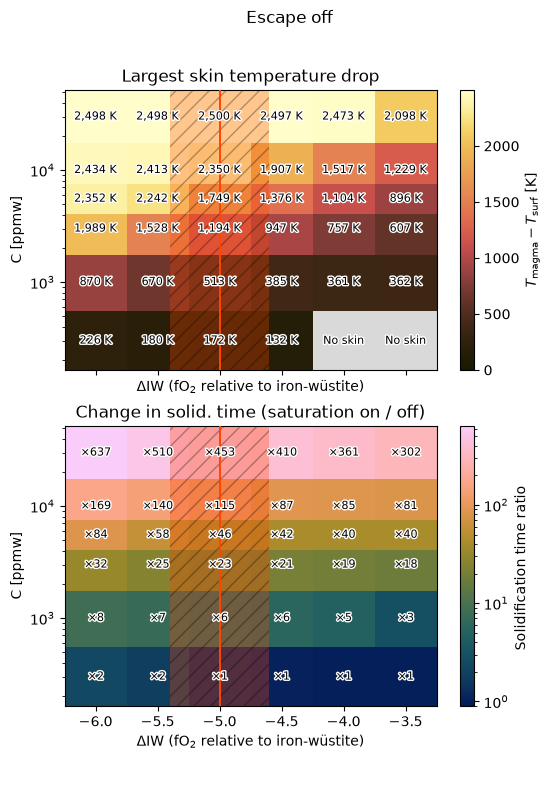

In [14]:
on, off = arm(True, ETA_OFF), arm(False, ETA_OFF)
Z_dTmax = on_plane("dT_skin_max", on)
Z_ratio = on_plane("time_end", on) / on_plane("time_end", off)
Z_stat = np.maximum(on_plane("status", on), on_plane("status", off))
nonsolid = lambda i, j: "" if Z_stat[i, j] == 10 else "*"

no_skin = Z_dTmax <= 0
norm_dT = Normalize(vmin=0, vmax=np.nanmax(Z_dTmax))
r_lo, r_hi = np.nanmin(Z_ratio), np.nanmax(Z_ratio)
norm_r = LogNorm(vmin=min(r_lo, 0.9), vmax=max(r_hi, 1.1))

fig, axs = plt.subplots(2,1, figsize=(6,8), sharex=True)

pm = mesh(axs[0], Z_dTmax, cmc.lajolla, norm_dT, lambda i, j: f"{Z_dTmax[i, j]:,.0f} K", no_skin, "No skin")
fig.colorbar(pm, ax=axs[0], label=r"$T_\mathrm{magma} - T_\mathrm{surf}$ [K]")

cmap = deepcopy(cmc.batlow)
cmap.set_under("white")
pm = mesh(axs[1], Z_ratio, cmap, norm_r, lambda i, j: f"×{Z_ratio[i, j]:.0f}{nonsolid(i, j)}",
          np.zeros_like(no_skin), "")
fig.colorbar(pm, ax=axs[-1], label="Solidification time ratio ")

axs[0].set_title("Largest skin temperature drop")
axs[1].set_title("Change in solid. time (saturation on / off)")

for ax in axs:
    ax.axvspan(MERCURY_DIW - MERCURY_DIW_ERR, MERCURY_DIW + MERCURY_DIW_ERR,
               facecolor="orangered", edgecolor="k", hatch="//", lw=0, alpha=0.3, zorder=2)
    ax.axvline(MERCURY_DIW, color="orangered", ls="solid", lw=1.4, zorder=3)
    ax.set_yscale("log")
    ax.set_xlabel(r"$\Delta$IW (fO$_2$ relative to iron-wüstite)")
    ax.set_ylabel(C_label)

fig.suptitle(ESC_LABEL[ETA_OFF])
fig.legend(loc="outside lower center", frameon=False)
fig.savefig(os.path.join(outdir, "skin_thermal_grid.pdf"), bbox_inches="tight")
plt.show()

## Depth at which graphite is neutrally buoyant


In [15]:


DEPTH_MAX_KM = 60.0   # depth shown in the profile panels [km]

def neutral_depth(z, rho, rho_ref):
    """Shallowest depth [m] at which the mantle is denser than rho_ref, where sinking
    graphite would stop: 0 when the surface is already denser (the crust floats), and
    the depth of the mantle when no depth is."""
    denser = np.flatnonzero(rho >= rho_ref)
    if len(denser) == 0:
        return z[-1]
    i = denser[0]
    return 0.0 if i == 0 else np.interp(rho_ref, rho[i - 1:i + 1], z[i - 1:i + 1])

# SPIDER density profile (melt-solid mixture, at the mesh nodes) at every output time
# with a graphite crust: a saturated or held layer, above the solver's floor mass
profiles, rows = {}, []
for case, hf, x, y, on, e in zip(cases, helps, dIW, Cb, cond, eta):
    if not on:
        continue
    crust = hf[(np.array(hf["C_cd_kg"], dtype=float) > CONDENSATE_HELD_MASS_KG) & (hf["Time"] > 0)]
    snaps = []
    for (_, r), j in zip(crust.iterrows(), read_jsons(case, list(crust["Time"]))):
        if j is None:   # no interior output written at this time
            continue
        R = j.get_dict_values(["data", "radius_b"])
        rho = j.get_dict_values(["data", "rho_b"])
        z = R[0] - R
        snaps.append(dict(t=r["Time"], T=r["T_magma"], Phi=r["Phi_global"], z=z, rho=rho,
                          zn=neutral_depth(z, rho, RHO_GRAPHITE),
                          rf=float(j.get_dict_values(["rheological_front_phi", "depth"]))))
    if not snaps:
        continue
    profiles[(x, y, e)] = snaps
    zn = np.array([s["zn"] for s in snaps])
    k = int(np.argmax(zn))
    rows.append(dict(case=os.path.basename(case), dIW=x, C=y, eta=e, snapshots=len(snaps),
                     sinking=int(np.count_nonzero(zn > 0)), depth_max_km=zn[k] / 1e3,
                     t_max_yr=snaps[k]["t"] if zn[k] > 0 else np.nan,
                     T_magma_max=snaps[k]["T"] if zn[k] > 0 else np.nan,
                     Phi_max=snaps[k]["Phi"] if zn[k] > 0 else np.nan,
                     rho_top_min=min(s["rho"][0] for s in snaps), depth_end_km=zn[-1] / 1e3))
buoy = pd.DataFrame(rows).sort_values(["eta", "dIW", "C"]).reset_index(drop=True)

# Depth of the first node below the surface: a neutral depth shallower than this lies
# inside the first mesh cell, set by the surface node alone
z_node1 = next(iter(profiles.values()))[0]["z"][1]
buoy["resolved"] = buoy["depth_max_km"] > z_node1 / 1e3

# One panel per grid point: fO2 across, carbon budget up
dIW_v = np.unique(dIW[cond])
C_v = np.unique(Cb[cond])[::-1]
all_t = [s["t"] for snaps in profiles.values() for s in snaps]

buoy.to_csv(os.path.join(outdir, "graphite_neutral_buoyancy.csv"), index=False)
# buoy

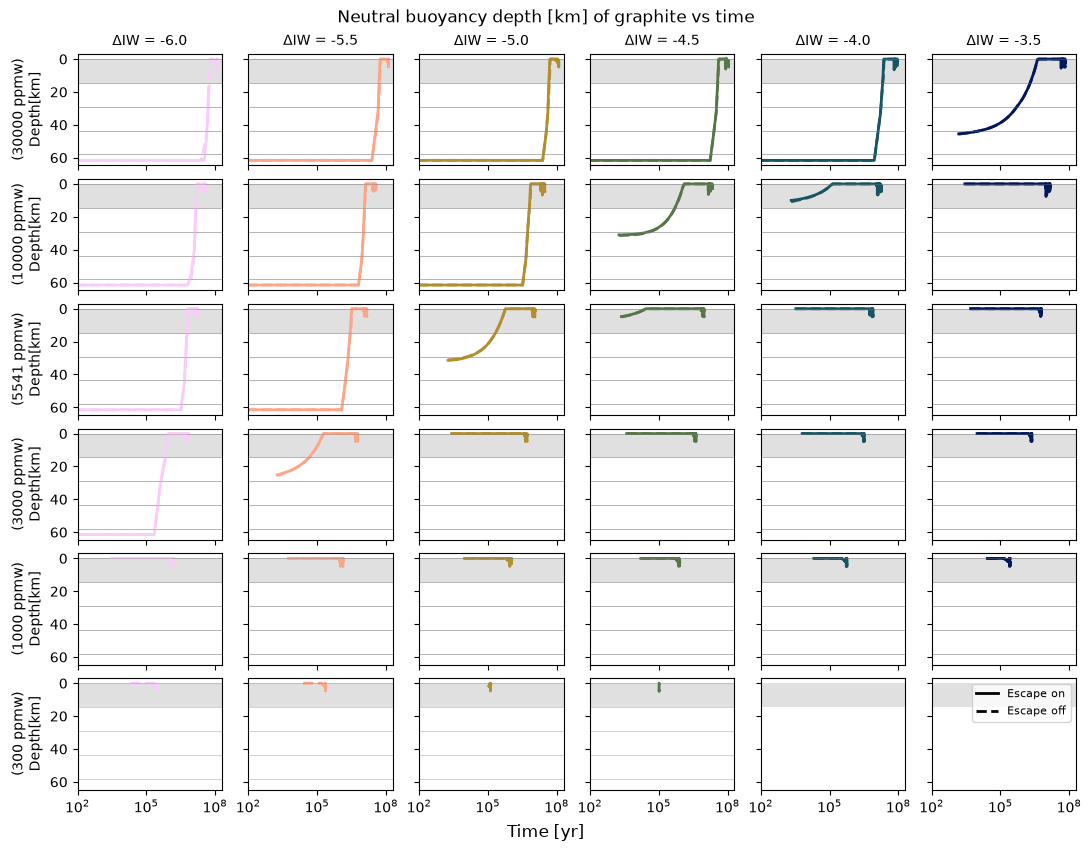

In [16]:
depth_top = max(s["zn"] for snaps in profiles.values() for s in snaps) / 1e3

def plot_neutral_depth_time():
    """Neutral buoyancy depth against time at each grid point, for escape efficiency e."""
    fig, axs = plt.subplots(len(C_v), len(dIW_v), figsize=(1.8 * len(dIW_v), 1.4 * len(C_v)),
                            sharex=True, sharey=True, squeeze=False, layout="constrained")
    

    # scalar mappable for the colour of the lines, by fO2
    cmap = cmc.batlow_r
    norm = BoundaryNorm(np.concatenate([dIW_v, [dIW_v[-1]]]), cmap.N)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

    for i, c in enumerate(C_v):
        for k, x in enumerate(dIW_v):
            ax = axs[i, k]
            ax.axhspan(0.0, z_node1 / 1e3, color="0.88", lw=0, zorder=0)


            for e in (ETA_OFF, ETA_ON):

                snaps = profiles.get((x, c, e))

                if snaps is not None:

                    if e == ETA_OFF:
                        ls = "--"
                    else:
                        ls = "-"

                    ax.plot([s["t"] for s in snaps], [s["zn"] / 1e3 for s in snaps], color=sm.to_rgba(x), 
                            lw=2, ls=ls)
                    
                    # add lines to show grid cells
                    for zz in snaps[-1]["z"]:
                        ax.axhline(zz / 1e3, color="0.5", lw=0.5, alpha=0.5)

            if i == 0:
                ax.set_title(rf"$\Delta$IW = {x:.1f}", fontsize=10)
            if k == 0:
                ax.set_ylabel(f"({c:.0f} ppmw)\nDepth[km]", fontsize=10)

    axs[0, 0].set_xscale("log")
    axs[0,0].set_xlim(left=1e2, right=1.5 * max(all_t))

    axs[-1,-1].legend([Line2D([], [], color="k", lw=2, ls="-"), Line2D([], [], color="k", lw=2, ls="--")],
                  ["Escape on", "Escape off"], loc="upper right", fontsize=8)
    
    fig.supxlabel("Time [yr]")
    axs[0, 0].set_ylim(1.05 * depth_top, -0.05 * depth_top)   # depth down; a floating crust at 0 stays visible
    fig.suptitle("Neutral buoyancy depth [km] of graphite vs time")
    fig.savefig(os.path.join(outdir, f"graphite_neutral_buoyancy_time_eta{e:g}.pdf"),
                bbox_inches="tight")
    plt.show()

plot_neutral_depth_time()

### Neutral buoyancy depth and rheological front in one panel

One fO2 (`DIW_SINGLE`), every carbon budget with a crust, both escape settings, in one panel: the colour gives the carbon budget and the line style the escape setting. The dotted line is the rheological front of the escape-on run, at the output times with a crust. The front is SPIDER's `rheological_front_phi`: the shallowest node whose melt fraction is below `interior_energetics.rfront_loc`. The helpfile column `RF_depth` is a different front (SPIDER's `rheological_front_dynamic`, the inviscid-viscous crossover), which in these runs stops at the first node once crystallisation starts, because the top node stays molten.


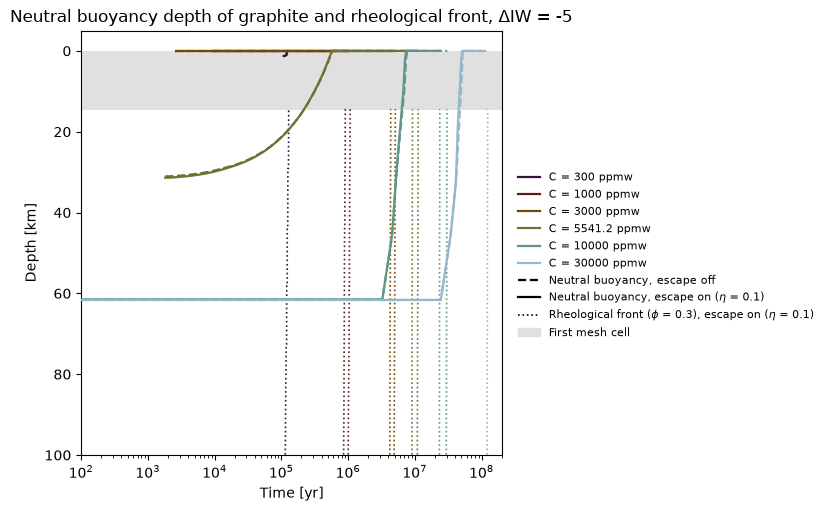

In [ ]:
DIW_SINGLE = MERCURY_DIW   # fO2 shown [delta IW]; must be on the grid's fO2 axis
RFRONT_PHI = lg.access_configs(cfgs, "interior_energetics.rfront_loc")[0]   # melt fraction at the front

def plot_neutral_depth_time_single(x_sel=DIW_SINGLE):
    """Neutral buoyancy depth against time at one fO2, all carbon budgets in one panel;
    the rheological front is drawn for the escape-on runs."""
    assert np.isclose(dIW_v, x_sel).any(), f"dIW = {x_sel} not among {dIW_v} with a crust"
    C_c = np.unique(Cb[cond])
    # evenly by rank; the palest end of glasgow is cut, as it vanishes on white
    col = {c: cmc.glasgow(0.85 * i / max(len(C_c) - 1, 1)) for i, c in enumerate(C_c)}
    esc_ls = {ETA_OFF: "--", ETA_ON: "-"}

    fig, ax = plt.subplots(figsize=(8.0, 5.0), layout="constrained")
    ax.axhspan(0.0, z_node1 / 1e3, color="0.88", lw=0, zorder=0)
    shown = set()
    for (x, c, e), snaps in sorted(profiles.items()):
        if not np.isclose(x, x_sel):
            continue
        shown.add(c)
        t = np.array([s["t"] for s in snaps])

        # get the neutral buoyancy depth for the last snapshot
        zn = np.array([s["zn"] for s in snaps])
        for i in range(1, len(zn)):
            if zn[i] > zn[i - 1]:
                zn[i] = zn[i - 1]

        ax.plot(t, zn / 1e3, color=col[c], lw=1.6, ls=esc_ls[e], zorder=3)
        
        if e == ETA_ON:
            ax.plot(t, [s["rf"] / 1e3 for s in snaps], color=col[c], lw=1.2, ls=":", zorder=2)

    ax.set_xscale("log")
    ax.set_xlim(left=1e2, right=1.5 * max(all_t))
    ax.set_ylim(100.0, -5.0)   # depth down
    ax.set_xlabel("Time [yr]")
    ax.set_ylabel("Depth [km]")
    ax.set_title(rf"Neutral buoyancy depth of graphite and rheological front, $\Delta$IW = {x_sel:g}")

    handles = [Line2D([], [], color=col[c], lw=1.6) for c in C_c if c in shown]
    labels = [f"C = {c:g} ppmw" for c in C_c if c in shown]
    handles += [Line2D([], [], color="k", lw=1.6, ls=esc_ls[e]) for e in (ETA_OFF, ETA_ON)]
    labels += [f"Neutral buoyancy, {ESC_LABEL[ETA_OFF].lower()}", f"Neutral buoyancy, {ESC_LABEL[ETA_ON].lower()}"]
    handles += [Line2D([], [], color="k", lw=1.2, ls=":"), Patch(color="0.88")]
    labels += [f"Rheological front ($\\phi$ = {RFRONT_PHI:g}), {ESC_LABEL[ETA_ON].lower()}", "First mesh cell"]
    fig.legend(handles, labels, loc="outside right center", frameon=False, fontsize=8)

    fig.savefig(os.path.join(outdir, f"graphite_neutral_buoyancy_time_single_dIW{x_sel:g}.pdf"),
                bbox_inches="tight")
    plt.show()

plot_neutral_depth_time_single()
